In [1]:
import logging

logging.getLogger("numexpr").setLevel(logging.ERROR)

from bravado.client import SwaggerClient
from IPython.display import display, Markdown
import pandas as pd
import nglview as nv
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole, MolsToGridImage

import teachopencadd

# Show up to 50 columns for DataFrames in this talktorial
pd.set_option("display.max_columns", 50)

In [2]:
species = "Human"
kinase_group = "TK"
kinase_family = "EGFR"
kinase_name = "EGFR"
ligand_expo_id = "IRE"

KLIFS_API_DEFINITIONS = "https://klifs.net/swagger/swagger.json"
KLIFS_CLIENT = SwaggerClient.from_url(KLIFS_API_DEFINITIONS, config={"validate_responses": False})

In [3]:
kinase_groups = KLIFS_CLIENT.Information.get_kinase_groups().response().result
# Note: IPython's display function can be used to render output as Markdown
display(Markdown("All kinase groups are returned as a list of strings:"))
print(kinase_groups)
# NBVAL_CHECK_OUTPUT

All kinase groups are returned as a list of strings:

['AGC', 'CAMK', 'CK1', 'CMGC', 'Other', 'STE', 'TK', 'TKL']


In [4]:
# Note: All code lines are supposed to be not longer than 99 characters
# Thus, sometimes brackets are used so that code lines can be split to multiple lines
# (you could also write this in one line without the brackets!)
kinase_families = (
    KLIFS_CLIENT.Information.get_kinase_families(kinase_group=kinase_group).response().result
)
display(Markdown(f"Kinase families in {kinase_group} are returned as a list of strings:"))
print(kinase_families)

Kinase families in TK are returned as a list of strings:

['ALK', 'Abl', 'Ack', 'Alk', 'Axl', 'CCK4', 'Csk', 'DDR', 'EGFR', 'Eph', 'FAK', 'FGFR', 'Fer', 'InsR', 'JakA', 'JakB', 'Lmr', 'Met', 'Musk', 'PDGFR', 'Ret', 'Ror', 'Ryk', 'Sev', 'Src', 'Syk', 'TK-Unique', 'Tec', 'Tie', 'Trk', 'VEGFR']


In [5]:
# Get kinase families for the TK group
kinase_families = (
    KLIFS_CLIENT.Information.get_kinase_families(kinase_group=kinase_group)
    .response()
    .result
)

display(Markdown(f"Kinase families in the **{kinase_group}** group:"))
print(kinase_families)

Kinase families in the **TK** group:

['ALK', 'Abl', 'Ack', 'Alk', 'Axl', 'CCK4', 'Csk', 'DDR', 'EGFR', 'Eph', 'FAK', 'FGFR', 'Fer', 'InsR', 'JakA', 'JakB', 'Lmr', 'Met', 'Musk', 'PDGFR', 'Ret', 'Ror', 'Ryk', 'Sev', 'Src', 'Syk', 'TK-Unique', 'Tec', 'Tie', 'Trk', 'VEGFR']


In [6]:
kinases = (
    KLIFS_CLIENT.Information.get_kinase_names(kinase_family=kinase_family, species=species)
    .response()
    .result
)
display(
    Markdown(
        f"Kinases in the {species.lower()} family {kinase_family} as a list of objects "
        f"that contain kinase-specific information:"
    )
)
kinases

Kinases in the human family EGFR as a list of objects that contain kinase-specific information:

[IDlist(full_name='epidermal growth factor receptor', kinase_ID=406, name='EGFR', species='Human'),
 IDlist(full_name='erb-b2 receptor tyrosine kinase 2', kinase_ID=407, name='ERBB2', species='Human'),
 IDlist(full_name='erb-b2 receptor tyrosine kinase 3', kinase_ID=408, name='ERBB3', species='Human'),
 IDlist(full_name='erb-b2 receptor tyrosine kinase 4', kinase_ID=409, name='ERBB4', species='Human')]

In [7]:
# Use iterator to get first element of the list
kinase_klifs_id = next(kinase.kinase_ID for kinase in kinases if kinase.name == kinase_name)
display(Markdown(f"Kinase KLIFS ID for {kinase_name}: {kinase_klifs_id}"))
# NBVAL_CHECK_OUTPUT

Kinase KLIFS ID for EGFR: 406

In [8]:
structures = (
    KLIFS_CLIENT.Structures.get_structures_list(kinase_ID=[kinase_klifs_id]).response().result
)
display(
    Markdown(
        f"Number of structures for the kinase {kinase_name}: {len(structures)}\n\n"
        f"Example structure, i.e. the first structure in the result list that contains a ligand:"
    )
)
# If structures do not contain ligands, the ligand field is set to 0
structure = next(structure for structure in structures if structure.ligand != 0)
structure

Number of structures for the kinase EGFR: 565

Example structure, i.e. the first structure in the result list that contains a ligand:

structureDetails(DFG='in', Grich_angle=48.1597, Grich_distance=14.8202, Grich_rotation=43.046, aC_helix='out', allosteric_ligand=0, alt='A', back=True, bp_III=False, bp_II_A_in=True, bp_II_B=False, bp_II_B_in=False, bp_II_in=True, bp_II_out=False, bp_IV=False, bp_I_A=True, bp_I_B=True, bp_V=False, chain='A', fp_I=False, fp_II=False, front=True, gate=True, kinase='EGFR', kinase_ID=406, ligand='W19', missing_atoms=0, missing_residues=0, pdb='3w33', pocket='KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQLMPFGCLLDYVREYLEDRRLVHRDLAARNVLVITDFGLA', quality_score=8.0, resolution=1.7, rmsd1=0.814, rmsd2=2.153, species='Human', structure_ID=782)

In [9]:
import pandas as pd

# 1. Assume 'structures' is the list of Bravado structure objects from your client call:
# structures = KLIFS_CLIENT.Structures.get_structures_list(kinase_ID=[kinase_klifs_id]).response().result

# 2. Map the attributes of each object into a clean list of dictionaries
structured_data = []
for s in structures:
  structured_data.append({
      "structure_ID": getattr(s, "structure_ID", None),
      "pdb": getattr(s, "pdb", None),
      "kinase": getattr(s, "kinase", None),
      "species": getattr(s, "species", None),
      "ligand": getattr(s, "ligand", None),
      "pocket": getattr(s, "pocket", None),
      "resolution": getattr(s, "resolution", None),
      "quality_score": getattr(s, "quality_score", None),
      "DFG": getattr(s, "DFG", None),
      "aC_helix": getattr(s, "aC_helix", None),
  })

# 3. Build the clean Pandas DataFrame
structures_df = pd.DataFrame(structured_data)

print(f"Successfully converted {len(structures_df)} structures into a clean DataFrame!")
display(structures_df.head(10))

Successfully converted 565 structures into a clean DataFrame!


,structure_ID,pdb,kinase,species,ligand,pocket,resolution,quality_score,DFG,aC_helix
0,782,3w33,EGFR,Human,W19,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,1.70,8.0,in,out
1,796,4ll0,EGFR,Human,YUN,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLIMQ...,4.00,8.5,in,in
2,783,2ito,EGFR,Human,IRE,KVLSSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,3.25,8.0,in,in
3,797,4li5,EGFR,Human,1WY,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.64,8.0,in,in
4,821,4jq8,EGFR,Human,KJ8,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.83,8.0,in,in
5,810,3lzb,EGFR,Human,ITI,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.70,7.6,in,out
6,775,4r5s,EGFR,Human,FI3,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,3.00,8.0,in,in
7,777,3vjo,EGFR,Human,ANP,KVLGS__FGTVYKVAIKE_EILDEAYVMASVDPHVCRLLGIQLITQ...,2.64,6.8,in,in
8,784,3w32,EGFR,Human,W32,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,1.80,8.0,in,out
9,800,3lzb,EGFR,Human,ITI,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.70,7.6,in,out


In [10]:
display(Markdown(f"Pocket sequence:\n\n{structure.pocket}\n\n({len(structure.pocket)} residues)"))

Pocket sequence:

KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQLMPFGCLLDYVREYLEDRRLVHRDLAARNVLVITDFGLA

(85 residues)

In [11]:
KLIFS_CLIENT.Interactions.get_interactions_get_types().response().result

[{'position': '1', 'name': 'Apolar contact'},
 {'position': '2', 'name': 'Aromatic face-to-face'},
 {'position': '3', 'name': 'Aromatic edge-to-face'},
 {'position': '4', 'name': 'Hydrogen bond donor (protein)'},
 {'position': '5', 'name': 'Hydrogen bond acceptor (protein)'},
 {'position': '6', 'name': 'Protein cation - ligand anion'},
 {'position': '7', 'name': 'Protein anion - ligand cation'}]

In [12]:
structure_klifs_id = structure.structure_ID
interaction_fingerprints = (
    KLIFS_CLIENT.Interactions.get_interactions_get_IFP(structure_ID=[structure_klifs_id])
    .response()
    .result
)
interaction_fingerprints

[{'structure_ID': 782,
  'IFP': '0000000000000010000001000000000000000000000000000000000000000000000000100000000000000000000000000010000001000000100000000000000000000000000000000000000000000000000000000000000000000000000001000000000000000000000000000000000000000000000000000000010000001000000100000000000000000000000000000000001000000100000010000001000000100000010011000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000100000010000001010000000000010000000000000'}]

In [13]:
complex_coordinates = (
    KLIFS_CLIENT.Structures.get_structure_get_pdb_complex(structure_ID=structures[0].structure_ID)
    .response()
    .result
)
# Show some example rows
complex_coordinates.split("\n")[100:110]

['ATOM     67  N   GLU A 709      18.017  26.733  45.799  1.00  0.00           N  ',
 'ATOM     68  CA  GLU A 709      17.685  25.527  46.562  1.00  0.00           C  ',
 'ATOM     69  C   GLU A 709      17.372  25.814  48.036  1.00  0.00           C  ',
 'ATOM     70  O   GLU A 709      16.634  25.071  48.672  1.00  0.00           O  ',
 'ATOM     71  CB  GLU A 709      18.816  24.503  46.474  1.00  0.00           C  ',
 'ATOM     72  CG  GLU A 709      18.851  23.724  45.177  1.00  0.00           C  ',
 'ATOM     73  CD  GLU A 709      19.877  22.613  45.199  1.00  0.00           C  ',
 'ATOM     74  OE1 GLU A 709      19.470  21.427  45.212  1.00  0.00           O  ',
 'ATOM     75  OE2 GLU A 709      21.088  22.925  45.212  1.00  0.00           O1-',
 'ATOM     76  N   THR A 710      17.928  26.893  48.572  1.00  0.00           N  ']

In [14]:
bioactivities = (
    KLIFS_CLIENT.Ligands.get_bioactivity_list_pdb(ligand_PDB=structure.ligand).response().result
)
display(
    Markdown(
        f"Number of ChEMBL bioactivity values available in KLIFS for example ligand {structure.ligand}: {len(bioactivities)}\n\n"
        f"Example bioactivity:"
    )
)
bioactivities[0]

Number of ChEMBL bioactivity values available in KLIFS for example ligand W19: 10

Example bioactivity:

{'pref_name': 'Dual specificity mitogen-activated protein kinase kinase 5',
 'accession': 'Q13163',
 'organism': 'Homo sapiens',
 'standard_type': 'IC50',
 'standard_relation': '=',
 'standard_value': '870.0',
 'standard_units': 'nM',
 'pchembl_value': '6.06'}

In [15]:
import pandas as pd
import requests

# Define the KLIFS API base URL
API_URL = "https://klifs.net/api"

# Fetch bioactivity values for Gefitinib (ligand PDB ID: "IRE")
ligand_expo_id = "IRE"
print(f"Fetching bioactivity data from KLIFS for ligand {ligand_expo_id}...")

response = requests.get(
    f"{API_URL}/bioactivity_list_pdb", params={"ligand_PDB": ligand_expo_id}
)
bioactivities = response.json()

print(
    f"Number of ChEMBL bioactivity values available in KLIFS for example ligand {ligand_expo_id}: {len(bioactivities)}"
)
print("\nExample bioactivity:")
display(bioactivities[0])

# Convert to a clean Pandas DataFrame for further analysis
bioactivities_df = pd.DataFrame(bioactivities)
display(
    bioactivities_df[
        [
            "pref_name",
            "accession",
            "organism",
            "standard_type",
            "standard_value",
            "standard_units",
            "pchembl_value",
        ]
    ].head(10)
)

Fetching bioactivity data from KLIFS for ligand IRE...
Number of ChEMBL bioactivity values available in KLIFS for example ligand IRE: 499

Example bioactivity:


{'pref_name': 'Acyl-CoA dehydrogenase family member 10',
 'accession': 'Q6JQN1',
 'organism': 'Homo sapiens',
 'standard_type': 'Kd',
 'standard_relation': '=',
 'standard_value': '33795.0',
 'standard_units': 'nM',
 'pchembl_value': '4.47'}

,pref_name,accession,organism,standard_type,standard_value,standard_units,pchembl_value
0,Acyl-CoA dehydrogenase family member 10,Q6JQN1,Homo sapiens,Kd,33795.0,nM,4.47
1,ATP-binding cassette sub-family G member 2,Q9UNQ0,Homo sapiens,EC50,300.0,nM,6.52
2,ATP-binding cassette sub-family G member 2,Q9UNQ0,Homo sapiens,IC50,500.0,nM,6.30
3,ATP-binding cassette sub-family G member 2,Q9UNQ0,Homo sapiens,IC50,3190.0,nM,5.50
4,ATP-binding cassette sub-family G member 2,Q9UNQ0,Homo sapiens,IC50,1260.0,nM,5.90
5,ATP-binding cassette sub-family G member 2,Q9UNQ0,Homo sapiens,IC50,1100.0,nM,5.96
6,ATP-binding cassette sub-family G member 2,Q9UNQ0,Homo sapiens,IC50,400.0,nM,6.40
7,Beta-secretase 1,P56817,Homo sapiens,IC50,20000.0,nM,4.70
8,Bile salt export pump,O95342,Homo sapiens,IC50,10900.0,nM,4.96
9,Bile salt export pump,O95342,Homo sapiens,IC50,10900.0,nM,4.96


In [16]:
import pandas as pd

# Convert list of dictionaries to a clean DataFrame
bioactivities_df = pd.DataFrame(bioactivities)

# Filter for IC50 measurements and sort by potency (highest pChembl value = strongest binding)
ic50_df = bioactivities_df[bioactivities_df["standard_type"] == "IC50"].copy()

# Convert pchembl_value to numeric for sorting
ic50_df["pchembl_value"] = pd.to_numeric(
    ic50_df["pchembl_value"], errors="coerce"
)
ic50_sorted = ic50_df.sort_values(by="pchembl_value", ascending=False)

print("Top most potent targets for Gefitinib (IRE):")
display(
    ic50_sorted[
        ["pref_name", "organism", "standard_value", "standard_units", "pchembl_value"]
    ].head(10)
)

Top most potent targets for Gefitinib (IRE):


,pref_name,organism,standard_value,standard_units,pchembl_value
89,Epidermal growth factor receptor erbB1,Homo sapiens,0.1,nM,10.00
222,Epidermal growth factor receptor erbB1,Homo sapiens,0.1,nM,10.00
94,Epidermal growth factor receptor erbB1,Homo sapiens,0.1,nM,10.00
110,Epidermal growth factor receptor erbB1,Homo sapiens,0.1,nM,10.00
156,Epidermal growth factor receptor erbB1,Homo sapiens,0.15,nM,9.82
157,Epidermal growth factor receptor erbB1,Homo sapiens,0.17,nM,9.77
93,Epidermal growth factor receptor erbB1,Homo sapiens,0.2,nM,9.70
111,Epidermal growth factor receptor erbB1,Homo sapiens,0.2,nM,9.70
91,Epidermal growth factor receptor erbB1,Homo sapiens,0.2,nM,9.70
221,Epidermal growth factor receptor erbB1,Homo sapiens,0.32,nM,9.49


In [17]:
import pandas as pd
import requests

API_URL = "https://klifs.net/api"

# Use 'structure_ID' parameter (matching the Swagger definition for interactions)
struct_id = (
    structures_df["structure_ID"].values[0]
    if "structures_df" in locals() and not structures_df.empty
    else 782
)

print(
    f"Requesting interaction fingerprint for structure ID: {struct_id}..."
)
ifp_response = requests.get(
    f"{API_URL}/interactions_get_IFP", params={"structure_ID": struct_id}
)

# Safely check if the response is actually JSON/list before calling .get()
if ifp_response.status_code == 200:
  data = ifp_response.json()
  if isinstance(data, list) and len(data) > 0 and isinstance(data[0], dict):
    raw_ifp = data[0].get("IFP", "")
    print(f"Successfully retrieved IFP bitstring of length {len(raw_ifp)}!")
    print(f"Bitstring preview: {raw_ifp[:50]}...")
  else:
    print(
        "API returned an unexpected format or empty list:",
        data,
    )
else:
  print(f"API request failed with status code {ifp_response.status_code}")

Requesting interaction fingerprint for structure ID: 782...
Successfully retrieved IFP bitstring of length 595!
Bitstring preview: 00000000000000100000010000000000000000000000000000...


In [20]:
structures_df

,structure_ID,pdb,kinase,species,ligand,pocket,resolution,quality_score,DFG,aC_helix
0,782,3w33,EGFR,Human,W19,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,1.70,8.0,in,out
1,796,4ll0,EGFR,Human,YUN,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLIMQ...,4.00,8.5,in,in
2,783,2ito,EGFR,Human,IRE,KVLSSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,3.25,8.0,in,in
3,797,4li5,EGFR,Human,1WY,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.64,8.0,in,in
4,821,4jq8,EGFR,Human,KJ8,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.83,8.0,in,in
...,...,...,...,...,...,...,...,...,...,...
560,776,4i21,EGFR,Human,0,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLIMQ...,3.37,8.0,out-like,in
561,787,2eb2,EGFR,Human,0,KVLSSG___TVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.50,6.8,in,in
562,907,2rfe,EGFR,Human,0,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.90,8.0,in,out
563,798,4zjv,EGFR,Human,0,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQ...,2.70,8.0,out,in


In [21]:
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import requests

API_URL = "https://klifs.net/api"

if "structures_df" in locals() and not structures_df.empty:
  struct_ids = structures_df["structure_ID"].tolist()
else:
  struct_ids = [775, 777, 778, 779, 781]

print(f"Fetching {len(struct_ids)} IFPs in parallel (blazing fast)...")


# Define a helper function to fetch a single structure's IFP
def fetch_ifp(sid):
  try:
    resp = requests.get(
        f"{API_URL}/interactions_get_IFP", params={"structure_ID": sid}, timeout=5
    )
    if resp.status_code == 200:
      data = resp.json()
      item = data[0] if isinstance(data, list) and len(data) > 0 else data
      if isinstance(item, dict) and "IFP" in item:
        return {
            "structure_ID": item.get("structure_ID", sid),
            "interaction.fingerprint": item.get("IFP", ""),
        }
  except Exception:
    pass
  return None


# Execute requests concurrently using 16 threads
formatted_rows = []
with ThreadPoolExecutor(max_workers=16) as executor:
  results = executor.map(fetch_ifp, struct_ids)
  formatted_rows = [res for res in results if res is not None]

# Build the final clean DataFrame
ifp_summary_df = pd.DataFrame(formatted_rows)
pd.set_option("display.max_colwidth", 40)

print(
    f"\nSuccessfully retrieved {len(ifp_summary_df)} IFPs out of"
    f" {len(struct_ids)}!"
)
print("Show example IFPs:")
display(ifp_summary_df.head())

Fetching 565 IFPs in parallel (blazing fast)...

Successfully retrieved 508 IFPs out of 565!
Show example IFPs:


,structure_ID,interaction.fingerprint
0,782,000000000000001000000100000000000000...
1,796,000000000000001000000000000000000000...
2,783,000000000000001000000100000000000000...
3,797,000000000000001000000100000000000000...
4,821,000000000000001000000100000000000000...


In [22]:
import numpy as np
import pandas as pd

# 1. Convert all bitstrings from your dataframe into a 2D numeric array
ifp_matrix = np.array(
    [[int(bit) for bit in ifp] for ifp in ifp_summary_df["interaction.fingerprint"]]
)

# 2. Compute the average frequency of each interaction bit across all structures
avg_ifp = ifp_matrix.mean(axis=0)  # Shape: (595,)

# 3. Reshape the 595 vector into (85 residues, 7 interaction types)
reshaped_matrix = avg_ifp.reshape(85, 7)

# 4. Define the 7 interaction type labels
interaction_types = [
    "Apolar contact",
    "Aromatic face-to-face",
    "Aromatic edge-to-face",
    "Hydrogen bond donor (protein)",
    "Hydrogen bond acceptor (protein)",
    "Protein cation - ligand anion",
    "Protein anion - ligand cation",
]

# 5. Build the final Residue Feature Matrix DataFrame
residue_matrix_df = pd.DataFrame(reshaped_matrix, columns=interaction_types)
residue_matrix_df.index = range(1, 86)  # Pocket residue positions 1 to 85
residue_matrix_df.index.name = "pocket_residue"

print(f"Residue feature matrix shape: {residue_matrix_df.shape}")
display(residue_matrix_df.head(10))

Residue feature matrix shape: (85, 7)


,Apolar contact,Aromatic face-to-face,Aromatic edge-to-face,Hydrogen bond donor (protein),Hydrogen bond acceptor (protein),Protein cation - ligand anion,Protein anion - ligand cation
pocket_residue,,,,,,,
1,0.001969,0.000000,0.00000,0.000000,0.000000,0.0,0.0
2,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.0
3,0.976378,0.000000,0.00000,0.000000,0.003937,0.0,0.0
4,0.679134,0.000000,0.00000,0.000000,0.000000,0.0,0.0
5,0.322835,0.000000,0.00000,0.000000,0.000000,0.0,0.0
6,0.080709,0.000000,0.00000,0.000000,0.000000,0.0,0.0
7,0.000000,0.000000,0.00000,0.145669,0.003937,0.0,0.0
8,0.277559,0.007874,0.05315,0.007874,0.003937,0.0,0.0
9,0.003937,0.000000,0.00000,0.007874,0.000000,0.0,0.0


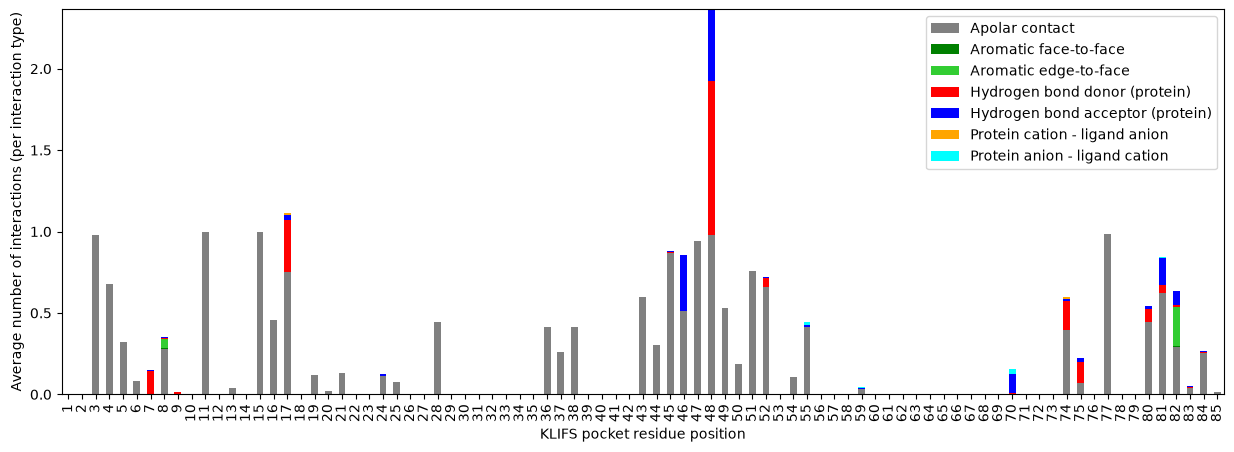

In [23]:
residue_matrix_df.plot.bar(
    figsize=(15, 5),
    stacked=True,
    xlabel="KLIFS pocket residue position",
    ylabel="Average number of interactions (per interaction type)",
    color=["grey", "green", "limegreen", "red", "blue", "orange", "cyan"],
);

In [24]:
# Filter for pocket residues that have at least one interaction across your structures
active_residues = residue_matrix_df[residue_matrix_df.sum(axis=1) > 0]

print(
    f"Out of 85 pocket residues, {len(active_residues)} actually interact with"
    " ligands in your dataset."
)
display(active_residues.head(15))

Out of 85 pocket residues, 48 actually interact with ligands in your dataset.


,Apolar contact,Aromatic face-to-face,Aromatic edge-to-face,Hydrogen bond donor (protein),Hydrogen bond acceptor (protein),Protein cation - ligand anion,Protein anion - ligand cation
pocket_residue,,,,,,,
1,0.001969,0.000000,0.00000,0.000000,0.000000,0.000000,0.0
3,0.976378,0.000000,0.00000,0.000000,0.003937,0.000000,0.0
4,0.679134,0.000000,0.00000,0.000000,0.000000,0.000000,0.0
5,0.322835,0.000000,0.00000,0.000000,0.000000,0.000000,0.0
6,0.080709,0.000000,0.00000,0.000000,0.000000,0.000000,0.0
7,0.000000,0.000000,0.00000,0.145669,0.003937,0.000000,0.0
8,0.277559,0.007874,0.05315,0.007874,0.003937,0.000000,0.0
9,0.003937,0.000000,0.00000,0.007874,0.000000,0.000000,0.0
10,0.003937,0.000000,0.00000,0.000000,0.000000,0.000000,0.0


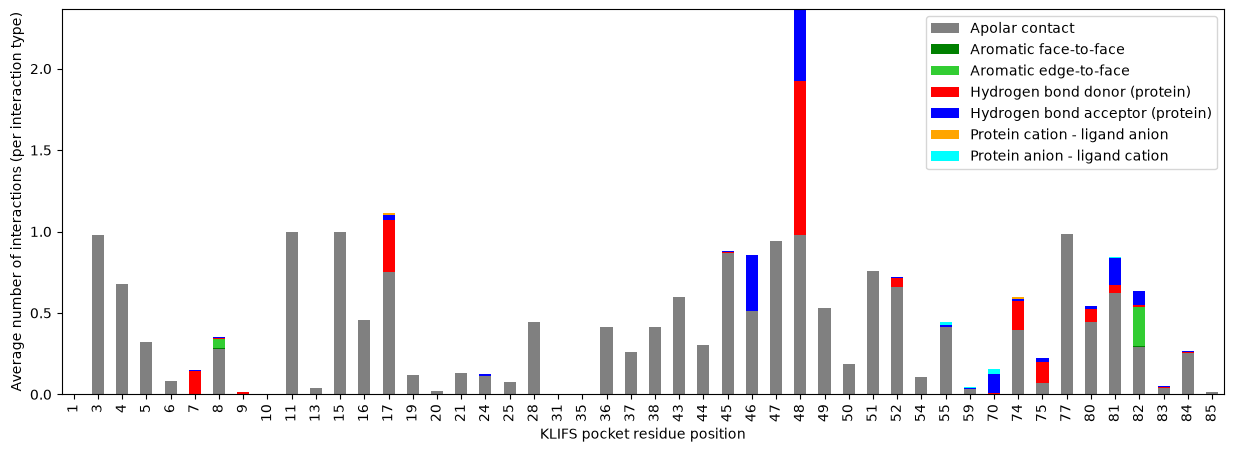

In [25]:
active_residues.plot.bar(
    figsize=(15, 5),
    stacked=True,
    xlabel="KLIFS pocket residue position",
    ylabel="Average number of interactions (per interaction type)",
    color=["grey", "green", "limegreen", "red", "blue", "orange", "cyan"],
);

In [42]:
subset = structures_df[(structures_df["ligand"] == ligand_expo_id)]
subset

,structure_ID,pdb,kinase,species,ligand,pocket,resolution,quality_score,DFG,aC_helix
2,783,2ito,EGFR,Human,IRE,KVLSSGAFGTVYKVAIKELEILDEAYVMASVDPHVC...,3.25,8.0,in,in
18,789,2itz,EGFR,Human,IRE,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVC...,2.72,9.4,in,in
20,790,2ity,EGFR,Human,IRE,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVC...,3.42,8.0,in,in
23,819,3ug2,EGFR,Human,IRE,KVLSSG___TVYKVAIKE_EILDEAYVMASVDPHVC...,2.50,7.6,in,in
42,823,4i22,EGFR,Human,IRE,KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVC...,1.71,8.0,in,out
47,837,4wkq,EGFR,Human,IRE,KVLGSG___TVYKVAIKE_EILDEAYVMASVDPHVC...,1.85,6.7,in,in
93,889,4wkq,EGFR,Human,IRE,KVLGSG___TVYKVAIKE_EILDEAYVMASVDPHVC...,1.85,6.7,in,in
98,898,3ug2,EGFR,Human,IRE,KVLSSG___TVYKVAIKE_EILDEAYVMASVDPHVC...,2.50,7.6,in,in


In [44]:
print (len(subset))

8


In [52]:
pdb_list = subset["pdb"]
pdb_list

2     2ito
18    2itz
20    2ity
23    3ug2
42    4i22
47    4wkq
93    4wkq
98    3ug2
Name: pdb, dtype: str

In [53]:
# Fix: Loop through the unique values in the 'pdb' column
pdb_list = subset["pdb"].dropna().unique()

for pdb in pdb_list:
    pdb_lower = str(pdb).strip().lower()
    filename = f"{pdb_lower}.pdb"
    url = f"https://files.rcsb.org/download/{filename}"
    urllib.request.urlretrieve(url, filename)
    print("Downloaded pdb successfully!")

    # 2. Load it using Biotite
    source_array = bsio.load_structure(filename, extra_fields=["charge"])

    # 3. Verification
    print(f"Successfully loaded structure! Total atoms: {len(source_array)}")

Downloaded pdb successfully!
Successfully loaded structure! Total atoms: 2484
Downloaded pdb successfully!
Successfully loaded structure! Total atoms: 2512
Downloaded pdb successfully!
Successfully loaded structure! Total atoms: 2446
Downloaded pdb successfully!
Successfully loaded structure! Total atoms: 2436
Downloaded pdb successfully!
Successfully loaded structure! Total atoms: 2575
Downloaded pdb successfully!
Successfully loaded structure! Total atoms: 2482


In [54]:
''' HOW TO DELETE PDB FILES:
from pathlib import Path

pdb_list = structures_df["pdb"].dropna().unique()

for pdb in pdb_list:
  # 1. Recreate the exact filename string for each item in the loop
  filename = f"{str(pdb).strip().lower()}.pdb"
  file_path = Path(filename)

  # 2. Check if it exists before unlinking so it doesn't crash
  if file_path.exists():
    file_path.unlink()
    print(f"Deleted {filename}")
  else:
    print(f"Skipped: {filename} (not found)")
'''

' HOW TO DELETE PDB FILES:\nfrom pathlib import Path\n\npdb_list = structures_df["pdb"].dropna().unique()\n\nfor pdb in pdb_list:\n  # 1. Recreate the exact filename string for each item in the loop\n  filename = f"{str(pdb).strip().lower()}.pdb"\n  file_path = Path(filename)\n\n  # 2. Check if it exists before unlinking so it doesn\'t crash\n  if file_path.exists():\n    file_path.unlink()\n    print(f"Deleted {filename}")\n  else:\n    print(f"Skipped: {filename} (not found)")\n'

In [1]:
'''PYMOL:
# 1. Load your reference structure
load 2ito.pdb

# 2. Clean up the base view
hide everything
show cartoon, 2ito
color white, 2ito

# 3. Automatically find and select the pocket residues touching the ligand 
# (PyMOL groups them into a selection you can use instantly)
select pocket_residues, byres (2ito and organic around 4.5)

# 4. Highlight them with a distinct color and style
show sticks, pocket_residues
color magenta, pocket_residues

# 5. Make the ligand pop out too
show sticks, organic and 2ito
color cyan, organic and 2ito and not elem C
'''
'''
# 1. Set up a clean, professional visual style
hide everything, 2ito
show cartoon, 2ito and not organic
show sticks, organic
color gray80, 2ito and not organic
color cyan, organic

# 2. Isolate and highlight the binding pocket residues
select pocket_residues, byres (2ito and organic around 4.5)
show sticks, pocket_residues and not organic
color lightorange, pocket_residues and not organic

# 3. Automatically calculate and display polar contacts / hydrogen bonds
distance h_bonds, organic, pocket_residues, 3.6, mode=2

# 4. Style the interaction dashes to look sharp and clean
set dash_radius, 0.08
set dash_color, yellow
hide label, h_bonds
'''
'''
# Select non-polar/hydrophobic pocket residues
select hydrophobic_pocket, pocket_residues and resn VAL+LEU+ILE+MET+PHE+TRP+PRO+ALA

# Show them as sticks in a distinct color (e.g., forest green)
show sticks, hydrophobic_pocket
color forest, hydrophobic_pocket

# Draw close contact lines (within 4.0 Å) for general packing
distance hydrophobic_contacts, organic, hydrophobic_pocket, 4.0
set dash_color, palegreen, hydrophobic_contacts
'''
'''
# Select charged residues in the pocket
select charged_pocket, pocket_residues and resn ASP+GLU+LYS+ARG+HIS

# Highlight them
show sticks, charged_pocket
color marine, charged_pocket

# Measure potential ionic contacts (within 4.0 Å)
distance salt_bridges, organic, charged_pocket, 4.0
set dash_color, hotpink, salt_bridges
'''
'''
# Select aromatic pocket residues
select aromatic_pocket, pocket_residues and resn PHE+TYR+TRP+HIS

# Highlight them
show sticks, aromatic_pocket
color purple, aromatic_pocket
'''

'\n# Select aromatic pocket residues\nselect aromatic_pocket, pocket_residues and resn PHE+TYR+TRP+HIS\n\n# Highlight them\nshow sticks, aromatic_pocket\ncolor purple, aromatic_pocket\n'